In [ ]:
from pathlib import Path
import random
import shutil


SOURCE_DIR = Path("assets")
OUTPUT_DIR = Path("dataset")

TRAIN_RATIO = 0.70
VAL_RATIO = 0.15
TEST_RATIO = 0.15

SEED = 42

IMAGE_EXTENSIONS = {
    ".jpg",
    ".jpeg",
    ".png",
}

random.seed(SEED)

classes = [
    directory
    for directory in SOURCE_DIR.iterdir()
    if directory.is_dir()
]

print("Classes found:")

for class_dir in classes:
    print(f"  - {class_dir.name}")

for split in ["train", "val", "test"]:
    for class_dir in classes:

        output_class_dir = OUTPUT_DIR / split / class_dir.name

        output_class_dir.mkdir(
            parents=True,
            exist_ok=True
        )

for class_dir in classes:

    class_name = class_dir.name

    # Get all images for this class
    images = [
        path
        for path in class_dir.iterdir()
        if path.is_file()
        and path.suffix.lower() in IMAGE_EXTENSIONS
    ]

    # Shuffle images
    random.shuffle(images)

    n = len(images)

    train_end = int(n * TRAIN_RATIO)
    val_end = train_end + int(n * VAL_RATIO)

    train_images = images[:train_end]
    val_images = images[train_end:val_end]
    test_images = images[val_end:]

    print(f"\nClass: {class_name}")
    print(f"Total: {n}")
    print(f"Train: {len(train_images)}")
    print(f"Val:   {len(val_images)}")
    print(f"Test:  {len(test_images)}")

    splits = {
        "train": train_images,
        "val": val_images,
        "test": test_images,
    }

    # Copy images
    for split_name, split_images in splits.items():

        destination = OUTPUT_DIR / split_name / class_name

        for image_path in split_images:

            shutil.copy2(
                image_path,
                destination / image_path.name
            )


print("\nDataset splitting completed.")
print(f"Output directory: {OUTPUT_DIR.resolve()}")

Classes found:
  - bad
  - good

Class: bad
Total: 174
Train: 121
Val:   26
Test:  27

Class: good
Total: 175
Train: 122
Val:   26
Test:  27

Dataset splitting completed.
Output directory: /Users/oussamahabiballah/ensa/1234/dataset


In [10]:
%pip install matplotlib

  Using cached matplotlib-3.11.2-cp311-cp311-macosx_10_12_x86_64.whl.metadata (80 kB)
  Using cached contourpy-1.3.3-cp311-cp311-macosx_10_9_x86_64.whl.metadata (5.5 kB)
  Using cached cycler-0.12.1-py3-none-any.whl.metadata (3.8 kB)
  Using cached fonttools-4.66.0-cp311-cp311-macosx_10_9_x86_64.whl.metadata (129 kB)
  Using cached kiwisolver-1.5.1-cp311-cp311-macosx_10_9_x86_64.whl.metadata (5.2 kB)
  Using cached pillow-12.3.0-cp311-cp311-macosx_10_10_x86_64.whl.metadata (9.1 kB)
  Using cached pyparsing-3.3.3-py3-none-any.whl.metadata (5.9 kB)
Using cached matplotlib-3.11.2-cp311-cp311-macosx_10_12_x86_64.whl (9.5 MB)
Using cached contourpy-1.3.3-cp311-cp311-macosx_10_9_x86_64.whl (288 kB)
Using cached cycler-0.12.1-py3-none-any.whl (8.3 kB)
Using cached fonttools-4.66.0-cp311-cp311-macosx_10_9_x86_64.whl (2.6 MB)
Using cached kiwisolver-1.5.1-cp311-cp311-macosx_10_9_x86_64.whl (66 kB)
Using cached pillow-12.3.0-cp311-cp311-macosx_10_10_x86_64.whl (5.4 MB)
Using cached pyparsing-3.3

In [12]:
%pip install scikit-learn seaborn

  Using cached scikit_learn-1.9.1-cp311-cp311-macosx_10_9_x86_64.whl.metadata (9.3 kB)
  Using cached seaborn-0.13.2-py3-none-any.whl.metadata (5.4 kB)
  Using cached scipy-1.17.1-cp311-cp311-macosx_14_0_x86_64.whl.metadata (62 kB)
  Using cached joblib-1.6.0-py3-none-any.whl.metadata (6.5 kB)
  Using cached narwhals-2.26.0-py3-none-any.whl.metadata (15 kB)
  Using cached cloudpickle-3.1.2-py3-none-any.whl.metadata (7.1 kB)
Using cached scikit_learn-1.9.1-cp311-cp311-macosx_10_9_x86_64.whl (8.8 MB)
Using cached seaborn-0.13.2-py3-none-any.whl (294 kB)
Using cached joblib-1.6.0-py3-none-any.whl (306 kB)
Using cached cloudpickle-3.1.2-py3-none-any.whl (22 kB)
Using cached narwhals-2.26.0-py3-none-any.whl (474 kB)
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 10.4/10.4 MB 9.4 MB/s  0:00:010.1 MB/s eta 0:00:01
Using cached scipy-1.17.1-cp311-cp311-macosx_14_0_x86_64.whl (22.7 MB)
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 8/8 [scikit-learn]0m 7/8 [scikit-learn]
Note: you may need to restart

In [29]:
import os
import numpy as np
import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import layers
import matplotlib.pyplot as plt
from sklearn.metrics import classification_report, confusion_matrix
import seaborn as sns


TRAIN_DIR     = "dataset/train"

VAL_DIR     = "dataset/val"
TEST_DIR    = "dataset/test"

CLASS_NAMES   = ["bad", "good"]
IMG_SIZE      = (224, 224)
BATCH_SIZE    = 16
EPOCHS        = 60
LEARNING_RATE = 1e-3
SEED          = 42

tf.random.set_seed(SEED)
np.random.seed(SEED)

print("TensorFlow version:", tf.__version__)
print("GPUs available:", tf.config.list_physical_devices("GPU"))

TensorFlow version: 2.16.2
GPUs available: []


In [ ]:
def load_datasets():
    def make_ds(directory_path, shuffle):
        return keras.utils.image_dataset_from_directory(
            directory_path,
            image_size=IMG_SIZE,
            batch_size=BATCH_SIZE,
            label_mode="categorical",
            shuffle=shuffle,
            seed=SEED,
        )

    train_ds = make_ds(TRAIN_DIR, shuffle=True)
    val_ds   = make_ds(VAL_DIR,   shuffle=False)
    test_ds  = make_ds(TEST_DIR,  shuffle=False)
    
    return train_ds, val_ds, test_ds

raw_train_ds, raw_val_ds, raw_test_ds = load_datasets()

Found 243 files belonging to 2 classes.


I0000 00:00:1788650490.176256   28124 gpu_device.cc:2043] Created device /job:localhost/replica:0/task:0/device:GPU:0 with 4149 MB memory:  -> device: 0, name: NVIDIA GeForce RTX 3060 Laptop GPU, pci bus id: 0000:01:00.0, compute capability: 8.6


Found 52 files belonging to 2 classes.
Found 54 files belonging to 2 classes.


In [ ]:

augmentation_layer = keras.Sequential([
    layers.RandomFlip("horizontal_and_vertical"),
    layers.RandomRotation(0.2),
    layers.RandomZoom(0.2),
    layers.RandomTranslation(height_factor=0.1, width_factor=0.1),
    layers.RandomBrightness(0.15),
    layers.RandomContrast(0.15),
], name="data_augmentation")

def preprocess_train(images, labels):
    images = tf.cast(images, tf.float32)
    images = augmentation_layer(images, training=True)
    return images, labels

def preprocess_eval(images, labels):
    images = tf.cast(images, tf.float32) 
    return images, labels

AUTOTUNE = tf.data.AUTOTUNE

train_ds = (raw_train_ds
            .map(preprocess_train, num_parallel_calls=AUTOTUNE)
            .prefetch(AUTOTUNE))

val_ds   = (raw_val_ds
            .map(preprocess_eval,  num_parallel_calls=AUTOTUNE)
            .prefetch(AUTOTUNE).cache())

test_ds  = (raw_test_ds
            .map(preprocess_eval,  num_parallel_calls=AUTOTUNE)
            .prefetch(AUTOTUNE).cache())

In [ ]:

def build_model(num_classes=3):
    base_model = keras.applications.EfficientNetB0(
        input_shape=(*IMG_SIZE, 3),
        include_top=False,
        weights="imagenet"
    )

    base_model.trainable = True
    total_layers = len(base_model.layers)
    freezing_ratio = 0.7
    fine_tune_at = int(freezing_ratio * total_layers)

    for layer in base_model.layers[:fine_tune_at]:
        layer.trainable = False

    inputs = keras.Input(shape=(*IMG_SIZE, 3))

    x = base_model(inputs, training=False) 
    
    from tensorflow.keras import regularizers

    x = layers.GlobalAveragePooling2D()(x)
    x = layers.Dropout(0.3)(x)

    outputs = layers.Dense(
        num_classes, 
        activation="softmax",
        kernel_regularizer=regularizers.l2(0.1)
    )(x)

    return keras.Model(inputs, outputs, name="colmatage_EfficientNetB0")

model = build_model(num_classes=len(CLASS_NAMES))
model.summary()

NameError: name 'CLASS_NAMES' is not defined

In [ ]:

def get_callbacks():
    return [
        keras.callbacks.ModelCheckpoint(
            "best_model.keras",
            monitor="val_accuracy",
            save_best_only=True,
            verbose=1,
        ),
        keras.callbacks.EarlyStopping(
            monitor="val_accuracy",
            patience=15,
            restore_best_weights=True,
            verbose=1,
        ),
        keras.callbacks.ReduceLROnPlateau(
            monitor="val_loss",
            factor=0.5,
            patience=7,
            min_lr=1e-7,
            verbose=1,
        ),
    ]

def plot_history(history):
    fig, axes = plt.subplots(1, 2, figsize=(14, 5))

    axes[0].plot(history.history["accuracy"],     label="Train")
    axes[0].plot(history.history["val_accuracy"], label="Val")
    axes[0].set_title("Accuracy")
    axes[0].set_xlabel("Epoch")
    axes[0].legend(); axes[0].grid(True, alpha=0.3)

    axes[1].plot(history.history["loss"],     label="Train")
    axes[1].plot(history.history["val_loss"], label="Val")
    axes[1].set_title("Loss")
    axes[1].set_xlabel("Epoch")
    axes[1].legend(); axes[1].grid(True, alpha=0.3)

    plt.tight_layout()
    plt.show()

Epoch 1/60


I0000 00:00:1788650516.313493   28657 service.cc:153] XLA service 0x76fb1c07fdb0 initialized for platform CUDA (this does not guarantee that XLA will be used). Devices:
I0000 00:00:1788650516.313599   28657 service.cc:161]   StreamExecutor [0]: NVIDIA GeForce RTX 3060 Laptop GPU, Compute Capability 8.6 (Driver: 13.0.0; Runtime: 12.9.0; Toolkit: 12.5.0; DNN: 9.24.0)
I0000 00:00:1788650516.998350   28657 dump_mlir_util.cc:269] disabling MLIR crash reproducer, set env var `MLIR_CRASH_REPRODUCER_DIRECTORY` to enable.
I0000 00:00:1788650519.043353   28657 cuda_dnn.cc:461] Loaded cuDNN version 92400
I0000 00:00:1788650519.478024   28657 dot_merger.cc:481] Merging Dots in computation: a_inference_one_step_on_data_26480__.316
E0000 00:00:1788650530.319766   28657 cuda_timer.cc:87] Delay kernel timed out: measured time has sub-optimal accuracy. There may be a missing warmup execution, please investigate in Nsight Systems.


 4/16 ━━━━━━━━━━━━━━━━━━━━ 0s 23ms/step - accuracy: 0.7656 - loss: 0.9521 

I0000 00:00:1788650541.998242   28657 device_compiler.h:208] Compiled cluster using XLA!  This line is logged at most once for the lifetime of the process.


13/16 ━━━━━━━━━━━━━━━━━━━━ 0s 22ms/step - accuracy: 0.8515 - loss: 0.7692

I0000 00:00:1788650544.731387   28654 dot_merger.cc:481] Merging Dots in computation: a_inference_one_step_on_data_26480__.316


16/16 ━━━━━━━━━━━━━━━━━━━━ 0s 1s/step - accuracy: 0.8645 - loss: 0.7361  
Epoch 1: val_accuracy improved from None to 0.98077, saving model to best_model.keras

Epoch 1: finished saving model to best_model.keras
16/16 ━━━━━━━━━━━━━━━━━━━━ 71s 2s/step - accuracy: 0.9177 - loss: 0.6046 - val_accuracy: 0.9808 - val_loss: 0.3937 - learning_rate: 0.0010
Epoch 2/60
16/16 ━━━━━━━━━━━━━━━━━━━━ 0s 33ms/step - accuracy: 0.9523 - loss: 0.4054
Epoch 2: val_accuracy did not improve from 0.98077
16/16 ━━━━━━━━━━━━━━━━━━━━ 1s 42ms/step - accuracy: 0.9671 - loss: 0.3775 - val_accuracy: 0.8462 - val_loss: 0.5167 - learning_rate: 0.0010
Epoch 3/60
13/16 ━━━━━━━━━━━━━━━━━━━━ 0s 31ms/step - accuracy: 0.9843 - loss: 0.3028
Epoch 3: val_accuracy did not improve from 0.98077
16/16 ━━━━━━━━━━━━━━━━━━━━ 1s 37ms/step - accuracy: 0.9794 - loss: 0.3122 - val_accuracy: 0.8654 - val_loss: 0.5163 - learning_rate: 0.0010
Epoch 4/60
16/16 ━━━━━━━━━━━━━━━━━━━━ 0s 30ms/step - accuracy: 0.9976 - loss: 0.2121
Epoch 4: val

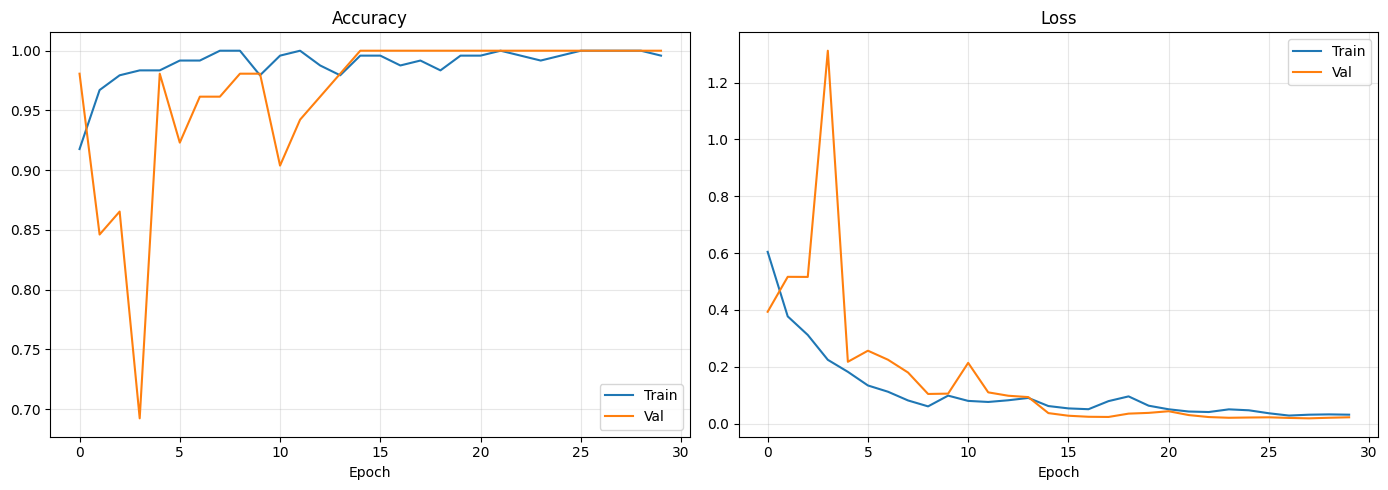

In [ ]:

model.compile(
    optimizer=keras.optimizers.Adam(learning_rate=LEARNING_RATE),
    loss="categorical_crossentropy",
    metrics=["accuracy"],
)

history = model.fit(
    train_ds,
    validation_data=val_ds,
    epochs=EPOCHS,
    callbacks=get_callbacks(),
)

plot_history(history)


══ Final Evaluation on Test Set ══
4/4 ━━━━━━━━━━━━━━━━━━━━ 0s 14ms/step - accuracy: 1.0000 - loss: 0.0300
Test Loss:     0.0300
Test Accuracy: 1.0000

── Classification Report ──
              precision    recall  f1-score   support

         bad       1.00      1.00      1.00        27
        good       1.00      1.00      1.00        27

    accuracy                           1.00        54
   macro avg       1.00      1.00      1.00        54
weighted avg       1.00      1.00      1.00        54



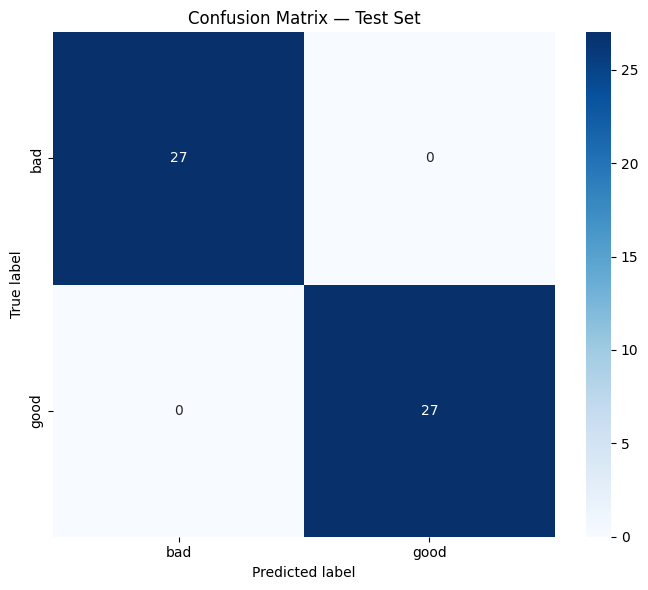

In [ ]:
def evaluate_test(model, test_ds):
    print("\n══ Final Evaluation on Test Set ══")
    test_loss, test_acc = model.evaluate(test_ds, verbose=1)
    print(f"Test Loss:     {test_loss:.4f}")
    print(f"Test Accuracy: {test_acc:.4f}")

    y_true, y_pred = [], []
    for images, labels in test_ds:
        preds = model.predict(images, verbose=0)
        y_true.extend(np.argmax(labels.numpy(), axis=1))
        y_pred.extend(np.argmax(preds, axis=1))

    print("\n── Classification Report ──")
    print(classification_report(y_true, y_pred, target_names=CLASS_NAMES))

    cm = confusion_matrix(y_true, y_pred)
    plt.figure(figsize=(7, 6))
    sns.heatmap(cm, annot=True, fmt="d", cmap="Blues",
                xticklabels=CLASS_NAMES, yticklabels=CLASS_NAMES)
    plt.ylabel("True label")
    plt.xlabel("Predicted label")
    plt.title("Confusion Matrix — Test Set")
    plt.tight_layout()
    plt.show()

evaluate_test(model, test_ds)

model.save("model_final.keras")

In [15]:
def classify_image(image_path):
    IMG_SIZE      = (224, 224)
    image = keras.utils.load_img(
        image_path,
        target_size=IMG_SIZE,
        color_mode="rgb"
    )

    image_array = keras.utils.img_to_array(image)
    image_batch = tf.expand_dims(image_array, axis=0)

    probabilities = model.predict(image_batch, verbose=0)[0]
    predicted_index = int(np.argmax(probabilities))

    predicted_class = CLASS_NAMES[predicted_index]
    confidence = float(probabilities[predicted_index])

    plt.imshow(image)
    plt.axis("off")
    plt.title(f"{predicted_class} — {confidence:.2%}")
    plt.show()

    print("Prediction:", predicted_class)
    print("Confidence:", f"{confidence:.2%}")

    for class_name, probability in zip(CLASS_NAMES, probabilities):
        print(f"{class_name}: {probability:.2%}")

    return predicted_class, confidence

In [16]:
import tensorflow as tf
import numpy as np

model = tf.keras.models.load_model('model_final.keras')



In [18]:
%pip install Pillow

Note: you may need to restart the kernel to use updated packages.


In [3]:
import sys
print(sys.executable)

/usr/local/opt/python@3.11/bin/python3.11


In [2]:
%pip install Pillow

^C
Note: you may need to restart the kernel to use updated packages.


In [1]:
classify_image("/Users/oussamahabiballah/ensa/1234/final_tests2/20260907_090048.jpg")

NameError: name 'classify_image' is not defined

In [ ]:
test_dir = Path("")

NameError: name 'Path' is not defined

In [2]:
images = [
        path
        for path in test_dir.iterdir()
        if path.is_file()
        and path.suffix.lower() in IMAGE_EXTENSIONS
]

NameError: name 'test_dir' is not defined

In [32]:
images = map(str, images)

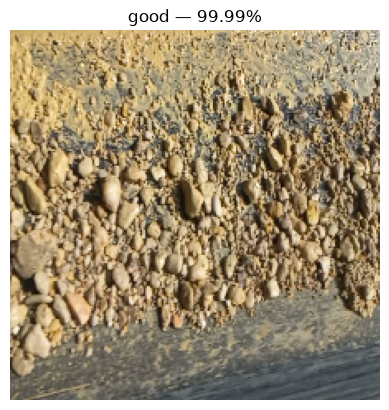

Prediction: good
Confidence: 99.99%
bad: 0.01%
good: 99.99%


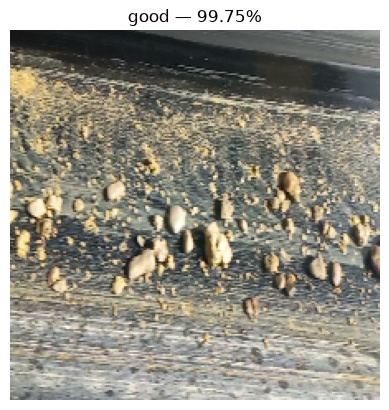

Prediction: good
Confidence: 99.75%
bad: 0.25%
good: 99.75%


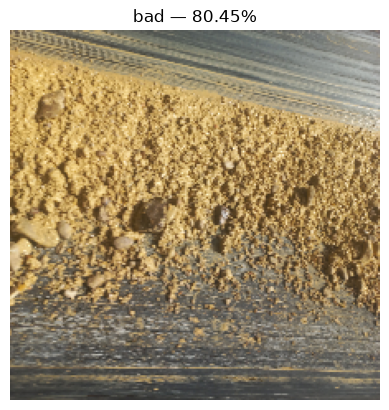

Prediction: bad
Confidence: 80.45%
bad: 80.45%
good: 19.55%


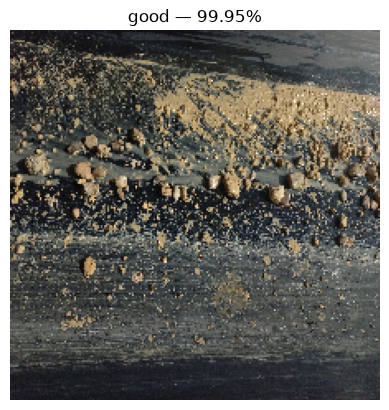

Prediction: good
Confidence: 99.95%
bad: 0.05%
good: 99.95%


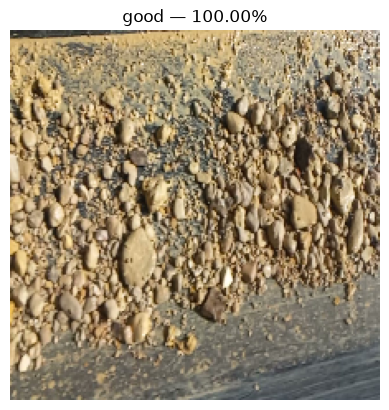

Prediction: good
Confidence: 100.00%
bad: 0.00%
good: 100.00%


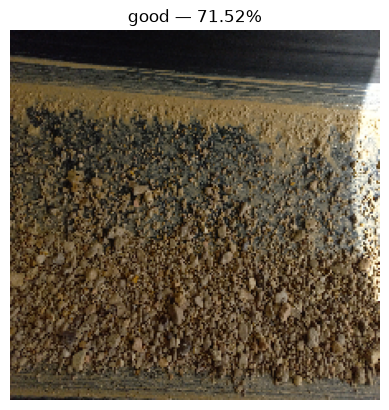

Prediction: good
Confidence: 71.52%
bad: 28.48%
good: 71.52%


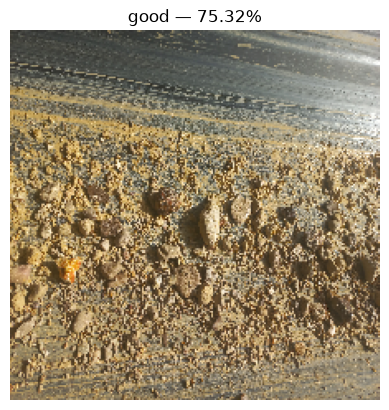

Prediction: good
Confidence: 75.32%
bad: 24.68%
good: 75.32%


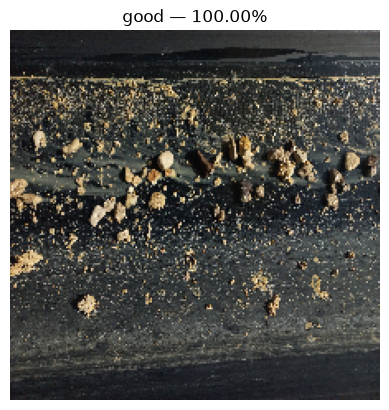

Prediction: good
Confidence: 100.00%
bad: 0.00%
good: 100.00%


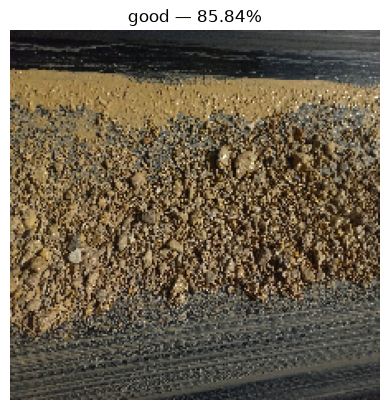

Prediction: good
Confidence: 85.84%
bad: 14.16%
good: 85.84%


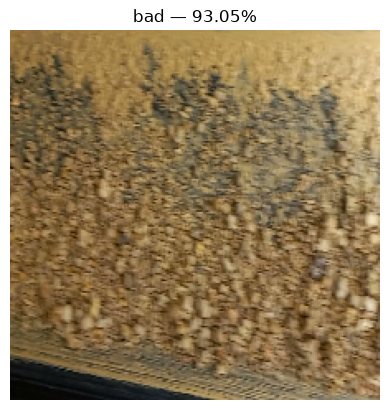

Prediction: bad
Confidence: 93.05%
bad: 93.05%
good: 6.95%


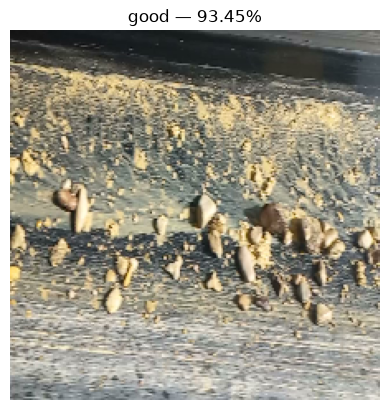

Prediction: good
Confidence: 93.45%
bad: 6.55%
good: 93.45%


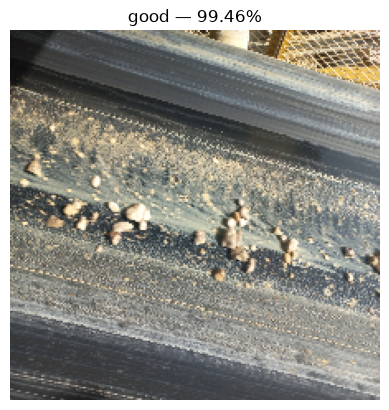

Prediction: good
Confidence: 99.46%
bad: 0.54%
good: 99.46%


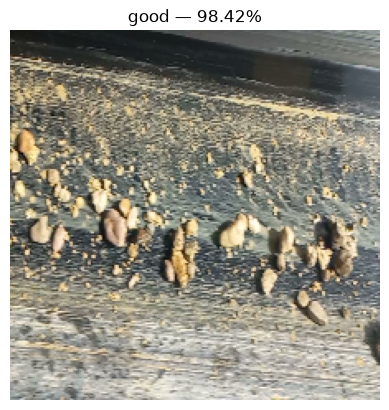

Prediction: good
Confidence: 98.42%
bad: 1.58%
good: 98.42%


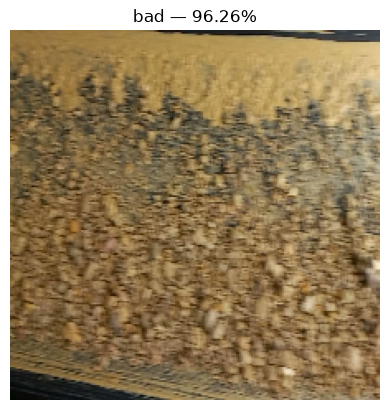

Prediction: bad
Confidence: 96.26%
bad: 96.26%
good: 3.74%


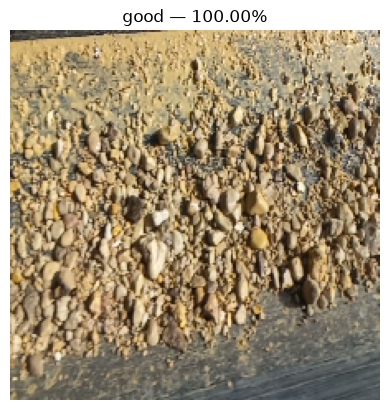

Prediction: good
Confidence: 100.00%
bad: 0.00%
good: 100.00%


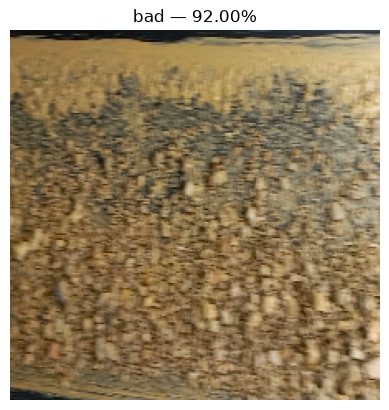

Prediction: bad
Confidence: 92.00%
bad: 92.00%
good: 8.00%


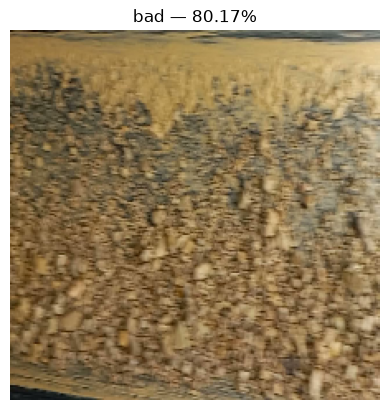

Prediction: bad
Confidence: 80.17%
bad: 80.17%
good: 19.83%


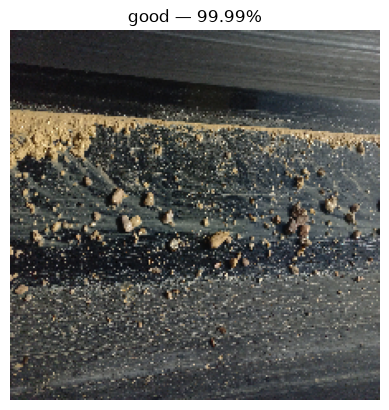

Prediction: good
Confidence: 99.99%
bad: 0.01%
good: 99.99%


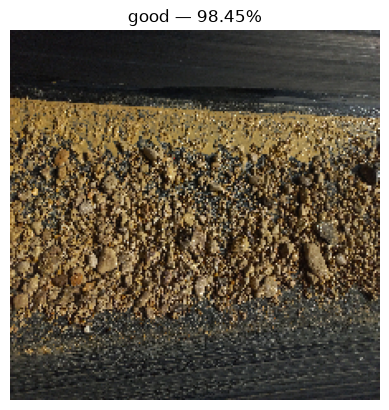

Prediction: good
Confidence: 98.45%
bad: 1.55%
good: 98.45%


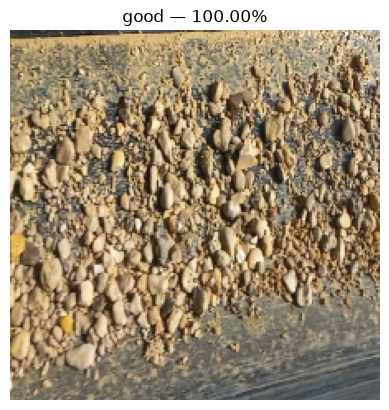

Prediction: good
Confidence: 100.00%
bad: 0.00%
good: 100.00%


In [33]:
for img in images:
    classify_image(img)